# 05 — Filtering, noise, and measurable tradeoffs

**Level:** Beginner → intermediate · 75–105 minutes  
**Prerequisites:** Read lessons 01–04: dtype, grayscale, histograms, and masks

## What you will build and learn

- Generate repeatable noise and retain a clean reference
- Compare mean, Gaussian, median, and bilateral filters
- Measure denoising error without overflow
- Choose parameters with evidence rather than appearance alone

## How to use this lesson

Run cells in order with **Shift+Enter**. Predict the result before running each example, then change one parameter and explain what changed. Every default example works offline after setup. Each notebook creates its own data, so previous notebooks do not need to have been run.

Try the exercises before reading the worked solutions. Use **Kernel → Restart Kernel and Run All Cells** to check that your work is reproducible. Keep your own changes in a duplicate notebook if you want to retain the reference version.


## Setup

The cell below imports the libraries and the small display/file helpers. Algorithms are written in the lesson cells. Color arrays passed to `show_images` are assumed to be BGR (OpenCV's usual order); the helper converts them to RGB for Matplotlib. Grayscale arrays are displayed directly. `rng` is a repeatable random generator, so running the notebook again reproduces its sample data.


In [1]:
from pathlib import Path
import sys

# Locate the project whether Jupyter starts in the project or notebooks folder.
start = Path.cwd().resolve()
ROOT = next((p for p in (start, *start.parents) if (p / "course_utils.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the OpenCV Practical project.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import cv2
import numpy as np
import matplotlib.pyplot as plt
from course_utils import show_images, make_scene, load_image, save_image

rng = np.random.default_rng(42)
cv2.setRNGSeed(42)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10})
print(f"OpenCV {cv2.__version__} | NumPy {np.__version__}")


OpenCV 4.14.0 | NumPy 2.5.3


## Step 1 — Build an image with known clean pixels

Denoising removes unwanted variation, but a filter cannot automatically know whether
a small feature is noise or useful detail. We will keep a clean reference and add
noise ourselves. This lets us measure error exactly in a controlled experiment.
The clean image contains flat regions, hard edges, a gradient, and thin text strokes.


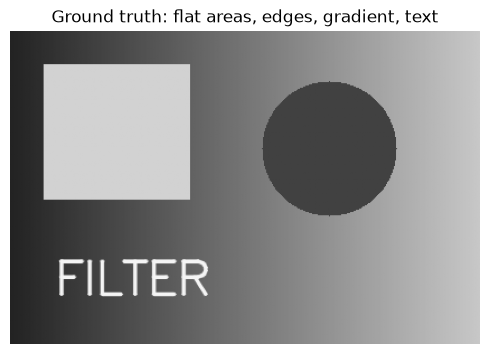

In [2]:
clean = np.tile(np.linspace(35, 200, 420, dtype=np.uint8), (280, 1))
cv2.rectangle(clean, (30, 30), (160, 150), 210, -1)
cv2.circle(clean, (285, 105), 60, 65, -1)
cv2.putText(clean, "FILTER", (40, 235), cv2.FONT_HERSHEY_SIMPLEX, 1.4, 245, 2, cv2.LINE_AA)
show_images([clean], ["Ground truth: flat areas, edges, gradient, text"], cols=1)
assert clean.dtype == np.uint8


Gaussian noise adds a random offset to each pixel. `normal(0, sigma, shape)`
draws offsets with mean 0 and standard deviation `sigma`. Use float arithmetic before
clipping. A fixed random seed reproduces the same experiment, so changing a filter
does not secretly change its input too.


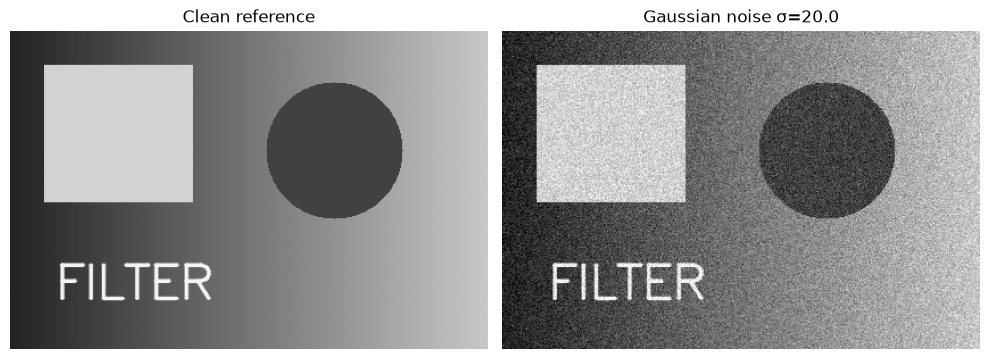

Noise before clipping: mean -0.076 standard deviation 20.069


In [3]:
noise_sigma = 20.0  # Try 8, 20, and 40 later.
noise_rng = np.random.default_rng(42)
noise = noise_rng.normal(0, noise_sigma, clean.shape)
gaussian_noisy = np.clip(clean.astype(np.float32) + noise, 0, 255).astype(np.uint8)
show_images([clean, gaussian_noisy], ["Clean reference", f"Gaussian noise σ={noise_sigma}"], cols=2)
print("Noise before clipping: mean", round(float(noise.mean()), 3),
      "standard deviation", round(float(noise.std()), 3))


Salt-and-pepper noise replaces some pixels with extreme dark or bright values.
`random(shape)` draws numbers from 0 up to, but excluding, 1. The same random field
decides which pixels become black and which become white. Compare the isolated outliers
with the fine-grained Gaussian noise. Noise type affects which filter works well.


Pixels changed: 5.9%


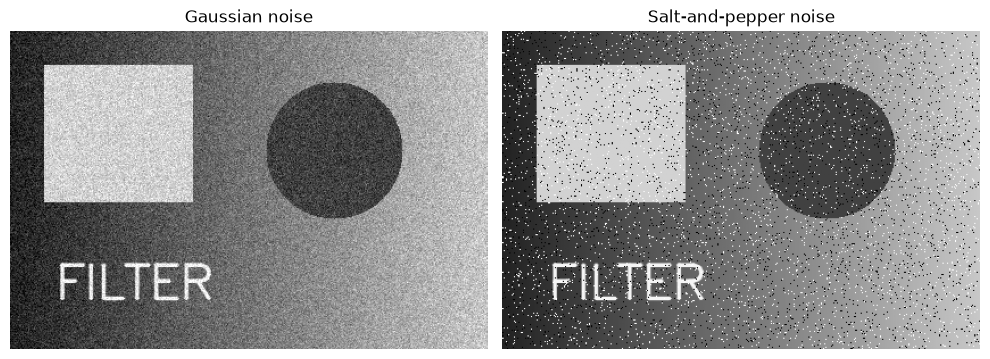

In [4]:
impulse_fraction = 0.06
impulse_rng = np.random.default_rng(7)
random_field = impulse_rng.random(clean.shape)
impulse_noisy = clean.copy()
impulse_noisy[random_field < impulse_fraction / 2] = 0
impulse_noisy[random_field > 1 - impulse_fraction / 2] = 255
actual_changed_fraction = float(np.mean(impulse_noisy != clean))
print(f"Pixels changed: {actual_changed_fraction:.1%}")
show_images([gaussian_noisy, impulse_noisy], ["Gaussian noise", "Salt-and-pepper noise"], cols=2)


## Step 2 — Understand a neighborhood average

A **kernel** describes a neighborhood and its weights. `blur(image, (k, k))` replaces
each pixel with an average over a k-by-k neighborhood. It reduces random variation,
but also mixes both sides of an edge. We use odd sizes so there is a natural center.
`filter2D` can apply custom weights; `ddepth=-1` keeps the input's output depth.


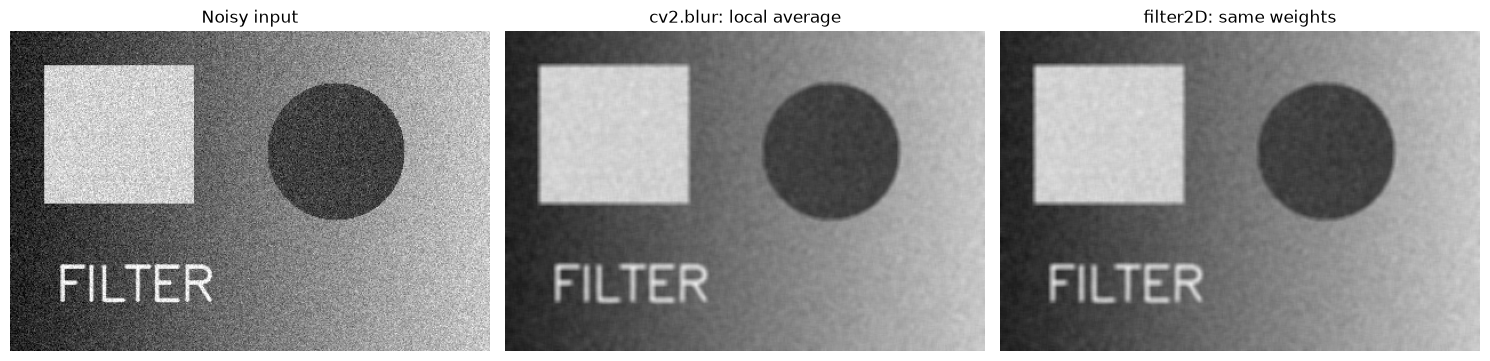

In [5]:
kernel_size = 5
box_filtered = cv2.blur(gaussian_noisy, (kernel_size, kernel_size))
average_kernel = np.ones((kernel_size, kernel_size), dtype=np.float32) / kernel_size ** 2
custom_average = cv2.filter2D(gaussian_noisy, ddepth=-1, kernel=average_kernel)
show_images([gaussian_noisy, box_filtered, custom_average],
            ["Noisy input", "cv2.blur: local average", "filter2D: same weights"])
assert abs(float(average_kernel.sum()) - 1.0) < 1e-6
# Different optimized integer paths may round by one gray level.
assert np.abs(box_filtered.astype(np.int16) - custom_average.astype(np.int16)).max() <= 1


## Step 3 — Compare filters designed for different needs

`GaussianBlur(image, (k, k), sigmaX)` gives greater weight to nearby pixels. `sigmaX=0`
lets OpenCV infer a scale from the kernel. `medianBlur(image, k)` chooses the middle
value in each neighborhood rather than averaging; isolated extreme values then have
less influence. Here k must be an odd integer greater than 1.


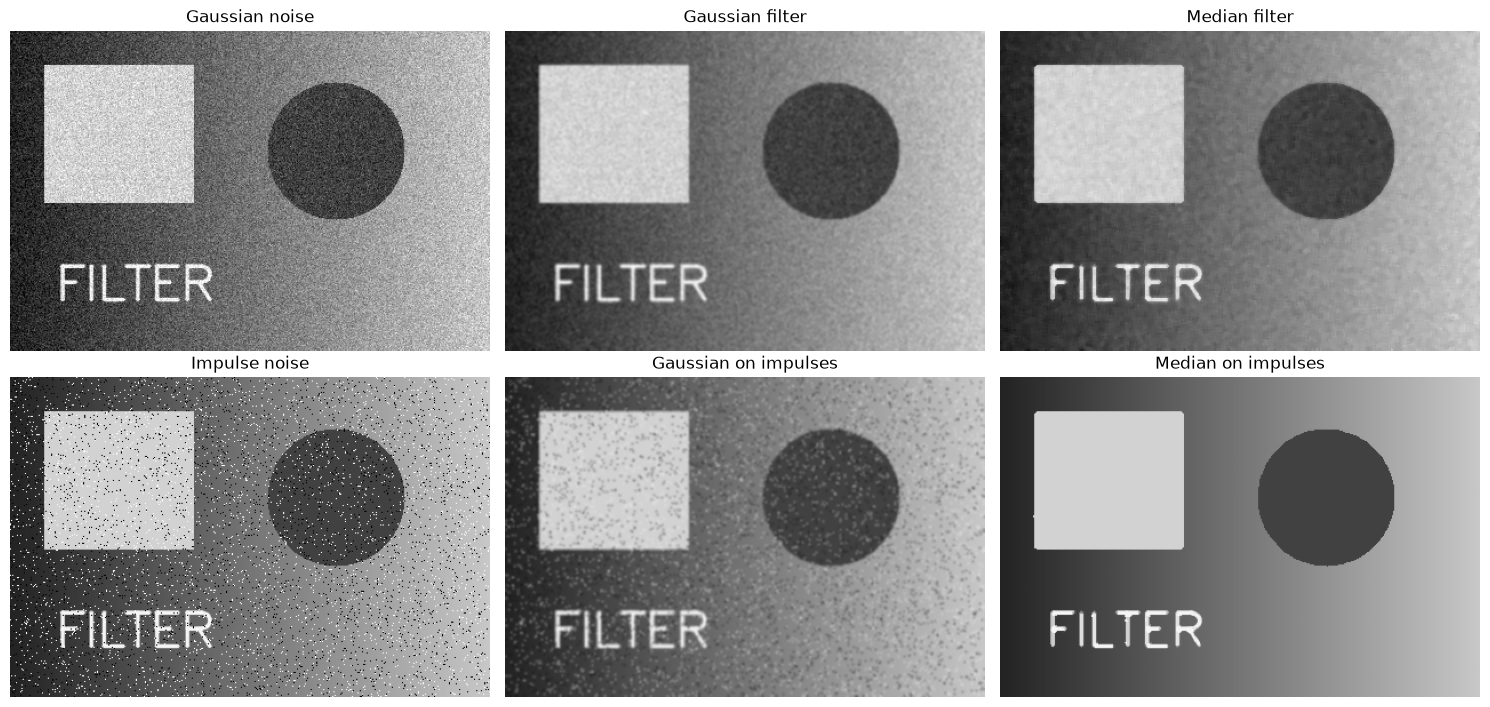

In [6]:
gaussian_filtered = cv2.GaussianBlur(gaussian_noisy, (5, 5), 0)
median_on_gaussian = cv2.medianBlur(gaussian_noisy, 5)
median_on_impulse = cv2.medianBlur(impulse_noisy, 5)
gaussian_on_impulse = cv2.GaussianBlur(impulse_noisy, (5, 5), 0)
show_images([gaussian_noisy, gaussian_filtered, median_on_gaussian,
             impulse_noisy, gaussian_on_impulse, median_on_impulse],
            ["Gaussian noise", "Gaussian filter", "Median filter",
             "Impulse noise", "Gaussian on impulses", "Median on impulses"], cols=3)


A bilateral filter uses both distance and intensity similarity: nearby pixels
with very different intensities receive less influence. In `bilateralFilter`, `d` is
the neighborhood diameter, `sigmaColor` sets the intensity-similarity scale, and
`sigmaSpace` sets the distance scale. It can preserve edges better, but costs more
computation and can flatten fine textures.


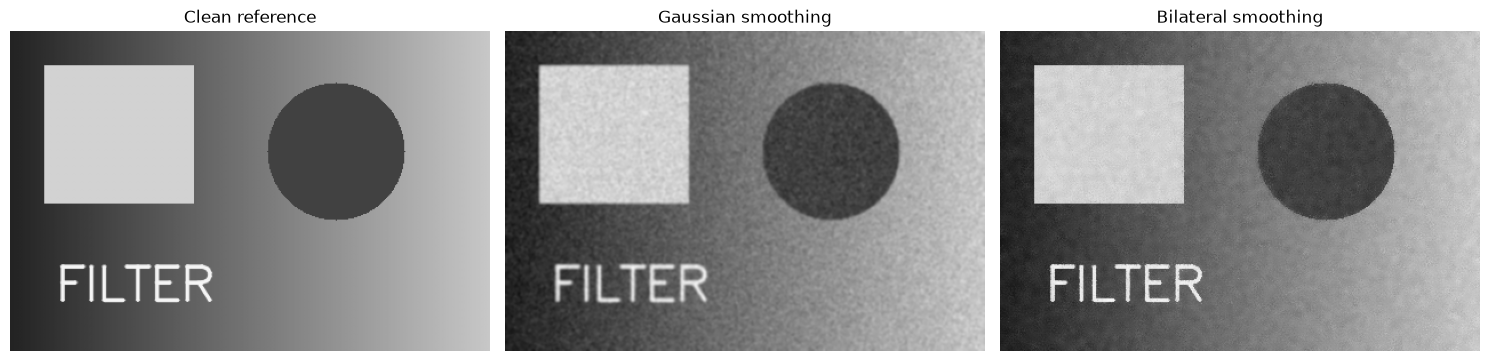

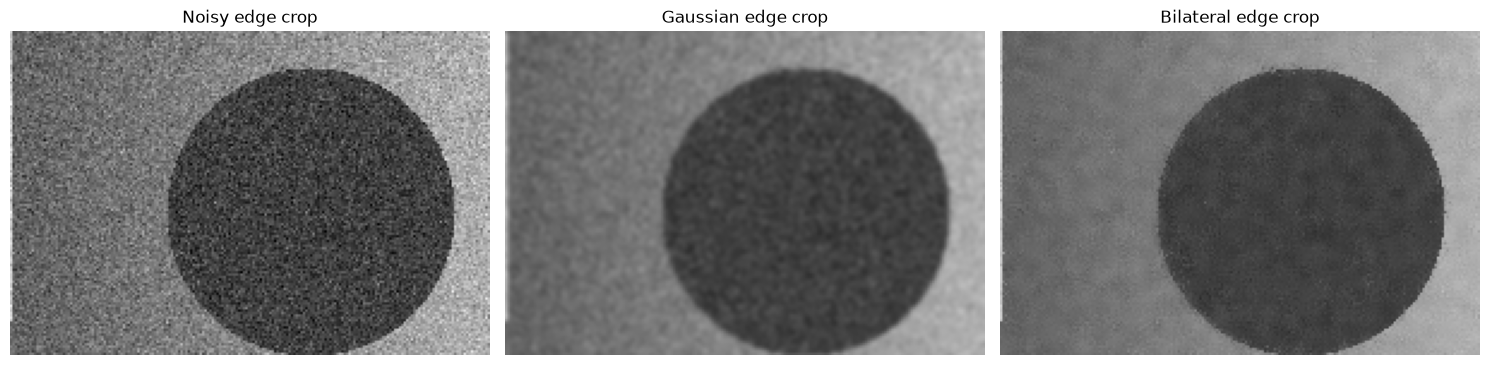

In [7]:
bilateral = cv2.bilateralFilter(gaussian_noisy, d=9, sigmaColor=40, sigmaSpace=40)
show_images([clean, gaussian_filtered, bilateral],
            ["Clean reference", "Gaussian smoothing", "Bilateral smoothing"])
# Inspect the same crop at the same display scale.
region = (slice(30, 165), slice(160, 360))
show_images([gaussian_noisy[region], gaussian_filtered[region], bilateral[region]],
            ["Noisy edge crop", "Gaussian edge crop", "Bilateral edge crop"])


## Step 4 — Measure the tradeoff instead of guessing

Mean squared error (MSE) averages squared differences from the clean reference; lower
is better for this metric. PSNR expresses that error on a logarithmic scale using the
maximum uint8 intensity 255; higher is better. An exact match gives infinite PSNR.
Neither score fully captures whether a face, text stroke, or important boundary survives.


In [8]:
def mse(reference, estimate):
    difference = reference.astype(np.float64) - estimate.astype(np.float64)
    return float(np.mean(difference ** 2))

def psnr(reference, estimate):
    error = mse(reference, estimate)
    return float("inf") if error == 0 else float(10 * np.log10(255.0 ** 2 / error))

assert mse(clean, clean) == 0
assert np.isinf(psnr(clean, clean))
gaussian_candidates = {
    "No filter": gaussian_noisy,
    "Box 5": box_filtered,
    "Gaussian 5": gaussian_filtered,
    "Median 5": median_on_gaussian,
    "Bilateral": bilateral,
}
for name, estimate in gaussian_candidates.items():
    print(f"{name:12} MSE={mse(clean, estimate):8.2f}   PSNR={psnr(clean, estimate):6.2f} dB")


No filter    MSE=  399.72   PSNR= 22.11 dB
Box 5        MSE=  107.65   PSNR= 27.81 dB
Gaussian 5   MSE=   73.47   PSNR= 29.47 dB
Median 5     MSE=   52.20   PSNR= 30.95 dB
Bilateral    MSE=   32.90   PSNR= 32.96 dB


A global average can hide a local problem. Compare a uniform patch inside the
rectangle with a strip crossing its edge. Less error in a smooth patch may accompany
more error at a boundary. We measure both using masks and display the actual sampling
locations so you can judge whether the comparison is fair.


No filter    flat MSE=  388.69  edge MSE=  426.67
Box 5        flat MSE=   14.64  edge MSE=  528.84
Gaussian 5   flat MSE=   27.17  edge MSE=  296.41
Median 5     flat MSE=   24.22  edge MSE=  118.05
Bilateral    flat MSE=   23.43  edge MSE=   68.98


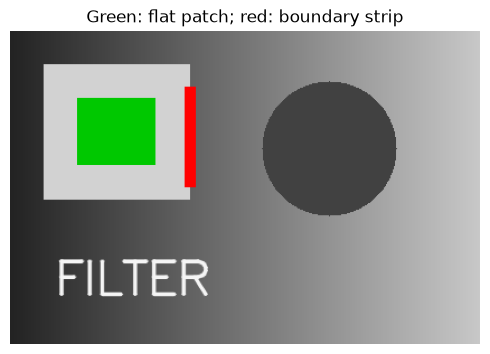

In [9]:
flat_mask = np.zeros_like(clean)
flat_mask[60:120, 60:130] = 255
edge_mask = np.zeros_like(clean)
edge_mask[50:140, 156:166] = 255

def masked_mse(reference, estimate, mask):
    squared = (reference.astype(np.float64) - estimate.astype(np.float64)) ** 2
    return float(squared[mask > 0].mean())

for name, estimate in gaussian_candidates.items():
    print(f"{name:12} flat MSE={masked_mse(clean, estimate, flat_mask):8.2f}"
          f"  edge MSE={masked_mse(clean, estimate, edge_mask):8.2f}")
marked = cv2.cvtColor(clean, cv2.COLOR_GRAY2BGR)
marked[flat_mask > 0] = (0, 200, 0)
marked[edge_mask > 0] = (0, 0, 255)
show_images([marked], ["Green: flat patch; red: boundary strip"], cols=1)


### Parameter experiment: when does a larger kernel hurt?

Run a small controlled sweep over kernel sizes. Keep the noise fixed. The lowest MSE
in this list is the best of these candidates on this image; it is not proof of a universal
best setting. Look at text as well as the numerical score.


k= 3: MSE=81.48
k= 5: MSE=73.47
k= 9: MSE=104.20
k=15: MSE=163.96


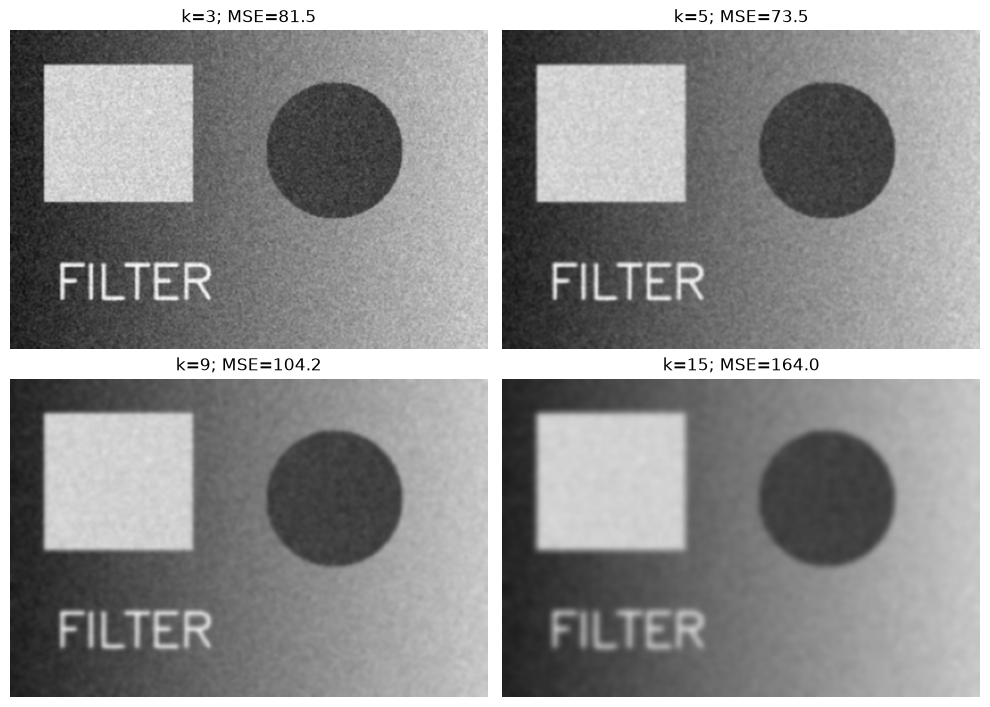

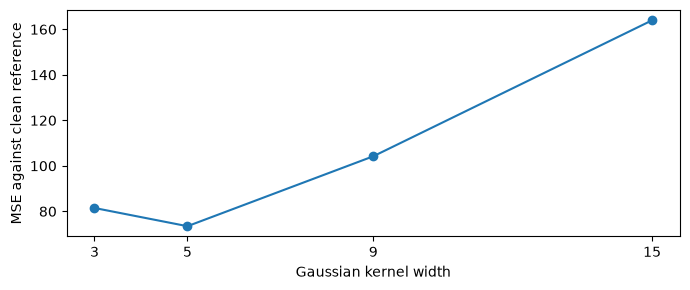

In [10]:
kernel_sizes = [3, 5, 9, 15]
sweep_images, sweep_scores = [], []
for k in kernel_sizes:
    filtered = cv2.GaussianBlur(gaussian_noisy, (k, k), 0)
    sweep_images.append(filtered)
    sweep_scores.append(mse(clean, filtered))
    print(f"k={k:2}: MSE={sweep_scores[-1]:.2f}")
show_images(sweep_images, [f"k={k}; MSE={score:.1f}" for k, score in zip(kernel_sizes, sweep_scores)], cols=2)
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(kernel_sizes, sweep_scores, "o-")
ax.set(xlabel="Gaussian kernel width", ylabel="MSE against clean reference", xticks=kernel_sizes)
plt.tight_layout()
plt.show()


## Step 5 — Inspect border behavior and filter assumptions

At the image boundary, part of a kernel falls outside the array. A border rule supplies
those missing values. `BORDER_CONSTANT` uses zero here; `BORDER_REPLICATE` repeats
the nearest edge value; `BORDER_REFLECT_101` mirrors neighboring values without repeating
the border pixel. Border choice changes results near edges even on a uniform image.


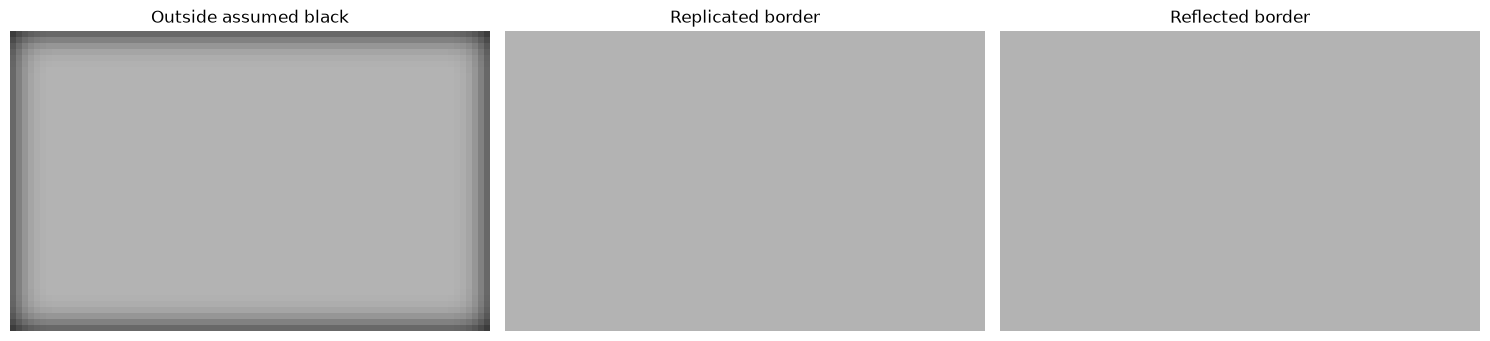

In [11]:
uniform = np.full((50, 80), 180, dtype=np.uint8)
zero_border = cv2.GaussianBlur(uniform, (15, 15), 0, borderType=cv2.BORDER_CONSTANT)
replicate_border = cv2.GaussianBlur(uniform, (15, 15), 0, borderType=cv2.BORDER_REPLICATE)
reflect_border = cv2.GaussianBlur(uniform, (15, 15), 0, borderType=cv2.BORDER_REFLECT_101)
show_images([zero_border, replicate_border, reflect_border],
            ["Outside assumed black", "Replicated border", "Reflected border"])
assert zero_border[0, 0] < 180
assert np.all(replicate_border == 180) and np.all(reflect_border == 180)


A row profile makes edge spreading visible as numbers. The clean rectangle has
a sharp change; averaging spreads it across nearby pixels. Noise reduction and edge
preservation therefore compete even when a blurred output initially looks pleasant.


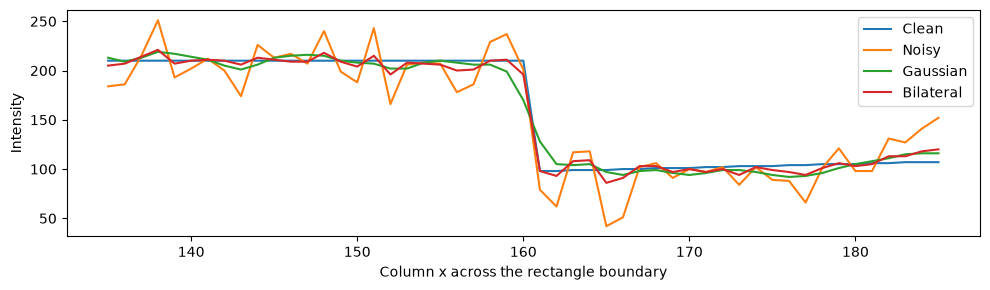

In [12]:
row = 90
fig, ax = plt.subplots(figsize=(10, 3))
for image, label in [(clean, "Clean"), (gaussian_noisy, "Noisy"),
                     (gaussian_filtered, "Gaussian"), (bilateral, "Bilateral")]:
    ax.plot(np.arange(135, 186), image[row, 135:186], label=label)
ax.set(xlabel="Column x across the rectangle boundary", ylabel="Intensity")
ax.legend()
plt.tight_layout()
plt.show()


## Step 6 — Mini-project: a small denoising benchmark

Evaluate the same filter families on both noise types. Store results, choose the
lowest-MSE candidate for each synthetic case, and save those outputs. In a real
application the clean reference is usually unavailable; you would use representative
validation data and task-level measures such as text-reading or detection accuracy.


For gaussian, best tested MSE: bilateral9


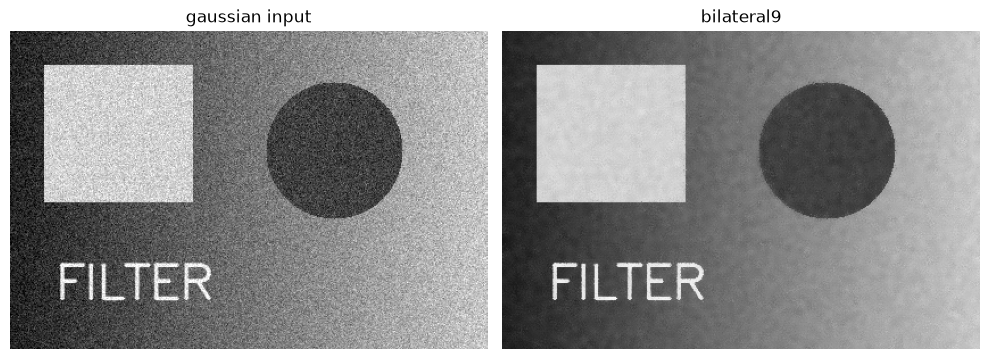

For impulse, best tested MSE: median5


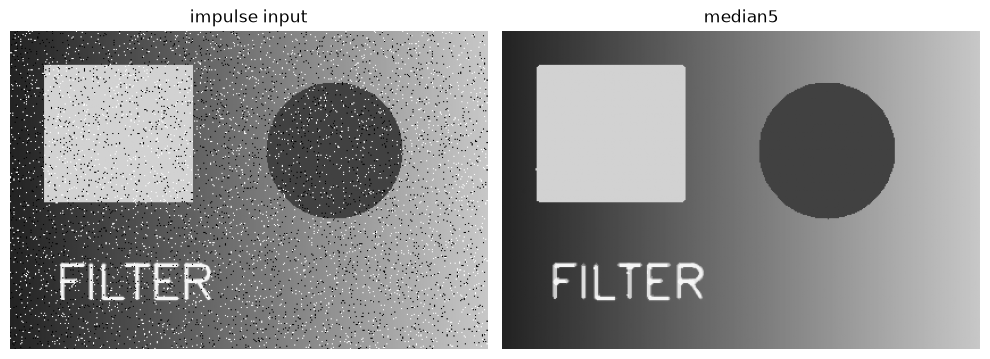

In [13]:
def filter_candidates(noisy):
    return {
        "unchanged": noisy,
        "gaussian5": cv2.GaussianBlur(noisy, (5, 5), 0),
        "median5": cv2.medianBlur(noisy, 5),
        "bilateral9": cv2.bilateralFilter(noisy, 9, 40, 40),
    }

lesson_dir = ROOT / "outputs" / "05_denoising"
lesson_dir.mkdir(parents=True, exist_ok=True)
benchmark = []
for noise_name, noisy in [("gaussian", gaussian_noisy), ("impulse", impulse_noisy)]:
    candidates = filter_candidates(noisy)
    best_name = min(candidates, key=lambda name: mse(clean, candidates[name]))
    for name, estimate in candidates.items():
        benchmark.append({"noise": noise_name, "filter": name,
                          "mse": mse(clean, estimate), "psnr": psnr(clean, estimate)})
    save_image(lesson_dir / f"{noise_name}_{best_name}.png", candidates[best_name])
    print(f"For {noise_name}, best tested MSE: {best_name}")
    show_images([noisy, candidates[best_name]], [noise_name + " input", best_name], cols=2)


In [14]:
import csv

benchmark_path = lesson_dir / "benchmark.csv"
with benchmark_path.open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=["noise", "filter", "mse", "psnr"])
    writer.writeheader()
    writer.writerows(benchmark)
print("Saved numerical comparison to:", benchmark_path)


Saved numerical comparison to: C:\Users\Hareram ray\AI\OpencvPractical\outputs\05_denoising\benchmark.csv


### Exercises — attempt first

1. Compare median kernels 3, 5, and 7 on the impulse-noise image. Which minimizes MSE?
2. Repeat Gaussian filtering with sigma 1.0 and 3.0 using the same 15×15 kernel.
   Does a fixed kernel imply a fixed amount of smoothing?
3. Create an identity kernel for `filter2D` that leaves every pixel unchanged.


In [15]:
# Your practice area. Keep the clean reference and noisy inputs unchanged.
# median_scores = ...


### Worked solutions

Changing sigma changes the Gaussian weights even when kernel dimensions stay fixed.
An identity kernel has only its center equal to one; all neighbors have zero weight.
Use explicit comparisons to confirm your expectations.


Median MSE by size: {3: 11.815204081632652, 5: 21.38465986394558, 7: 94.61722789115646}
Best tested median size: 3


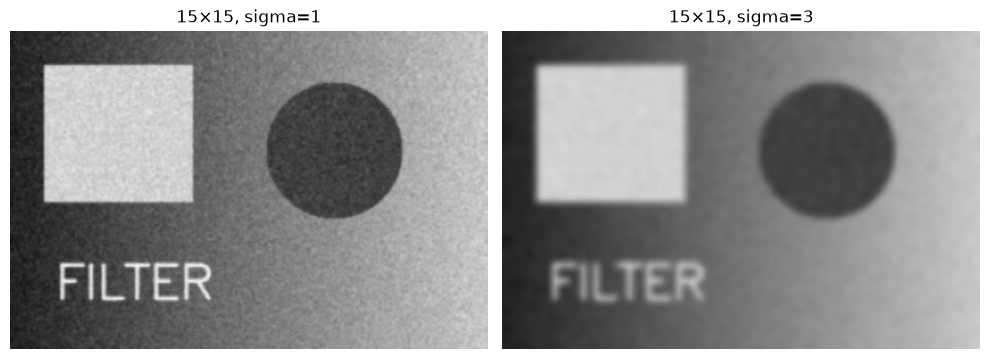

In [16]:
median_scores = {}
for k in [3, 5, 7]:
    median_scores[k] = mse(clean, cv2.medianBlur(impulse_noisy, k))
print("Median MSE by size:", median_scores)
print("Best tested median size:", min(median_scores, key=median_scores.get))

sigma_one = cv2.GaussianBlur(gaussian_noisy, (15, 15), sigmaX=1.0)
sigma_three = cv2.GaussianBlur(gaussian_noisy, (15, 15), sigmaX=3.0)
show_images([sigma_one, sigma_three], ["15×15, sigma=1", "15×15, sigma=3"], cols=2)
identity_kernel = np.zeros((3, 3), dtype=np.float32)
identity_kernel[1, 1] = 1
identity_result = cv2.filter2D(clean, -1, identity_kernel)
assert np.array_equal(identity_result, clean)


### Reflection

- Why did we convert to a floating-point type before computing error?
- Which noise type was most suited to a median filter? What happened to thin strokes?
- Why can a filter win in a flat patch but lose near an edge?
- What does a good score on a generated image fail to establish about real photographs?

Official references: [Smoothing and filtering](https://docs.opencv.org/4.x/d4/d13/tutorial_py_filtering.html),
[Filtering API and border modes](https://docs.opencv.org/4.x/d4/d86/group__imgproc__filter.html).
